# 04 · Model selection: find the best uplift model, fairly
**Why this step:** Step 3 showed targeting works, but its two models almost tied, and one 70/30 split is too noisy to pick a winner. Here we:
1. **Lock away 20% as a final exam** (40,008 customers), never touched while choosing.
2. **Compare 8 models with 5-fold cross-validation** on the other 80%: each model is trained 5 times, each time tested on a different fifth.
3. **Pick the champion by average score**, then confirm it on the locked 20%.
4. **Train the champion on everyone** and save uplift scores for all 400,162 customers.

Tuning (Optuna, 22 trials each for S and X) and repeat runs on 2 more random splits were done beforehand; their results are recorded in Cell 4.

In [1]:
%pip install -q lightgbm scikit-uplift

Note: you may need to restart the kernel to use updated packages.


## Cell 1 · Setup, data, and the locked final exam

In [2]:
import pandas as pd, numpy as np, duckdb, time, warnings, joblib
warnings.filterwarnings('ignore')
import matplotlib.pyplot as plt
from pathlib import Path
import lightgbm as lgb
from scipy.stats import rankdata
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.ensemble import HistGradientBoostingClassifier
from sklift.metrics import qini_auc_score, uplift_at_k
pd.set_option('display.width', 180)

FEAT = Path('..') / 'data_x5' / 'features'; MODELS = Path('..') / 'models'; MODELS.mkdir(exist_ok=True)
allp = duckdb.sql(f"SELECT * FROM '{(FEAT / 'customer_profiles.parquet').as_posix()}'").df()
allp = pd.concat([allp, pd.get_dummies(allp.gender, prefix='gender').astype(int)], axis=1)
X_COLS = [c for c in allp.columns if c not in {'client_id', 'gender', 'treatment_flg', 'target', 'in_experiment'}]
df = allp[allp.in_experiment == 1].reset_index(drop=True)
X = df[X_COLS].astype('float32'); T = df.treatment_flg.astype(int).values; Y = df.target.astype(int).values
strata = T * 2 + Y
dev_idx, hold_idx = train_test_split(np.arange(len(df)), test_size=0.20, stratify=strata, random_state=2026)
print(f'development {len(dev_idx):,} | locked final exam {len(hold_idx):,} | {len(X_COLS)} measures')

development 160,031 | locked final exam 40,008 | 69 measures


## Cell 2 · The candidate models
All use gradient-boosted trees inside; they differ in **how they turn predictions into uplift**.

| Model | Idea in one line |
|---|---|
| T-learner | Two models (messaged / not); uplift = difference |
| Class transformation | One model on a relabelled target; uplift = 2 × score − 1 |
| S-learner | One model with "was messaged" as an extra input; uplift = prediction with it on − with it off |
| X-learner | T-learner first, then a second stage learns each customer's *individual* gap directly |
| DR-learner (doubly robust) | Builds a corrected per-customer uplift estimate, then learns it; robust if one part is wrong |
| Ensemble | Average rank of S, X and DR: errors of one model are diluted by the others |

**HGB** = scikit-learn's boosted trees (used in Step 3). **LGBM** = LightGBM, a faster boosted-tree library with stronger regularisation.

In [3]:
def lgbc(**kw):
    p = dict(n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=400, subsample=0.8, subsample_freq=1,
             colsample_bytree=0.7, reg_lambda=5.0, verbose=-1, random_state=42); p.update(kw); return lgb.LGBMClassifier(**p)
def lgbr(**kw):
    p = dict(n_estimators=200, learning_rate=0.03, num_leaves=15, min_child_samples=800, subsample=0.8, subsample_freq=1,
             colsample_bytree=0.7, reg_lambda=10.0, verbose=-1, random_state=42); p.update(kw); return lgb.LGBMRegressor(**p)
def hgb():
    return HistGradientBoostingClassifier(learning_rate=0.05, max_iter=400, max_leaf_nodes=31, min_samples_leaf=200,
        l2_regularization=1.0, early_stopping=True, validation_fraction=0.1, n_iter_no_change=30, random_state=42)

def t_learner(make):
    def f(Xtr, t, y, Xte):
        a = make().fit(Xtr[t == 1], y[t == 1]); b = make().fit(Xtr[t == 0], y[t == 0])
        return a.predict_proba(Xte)[:, 1] - b.predict_proba(Xte)[:, 1]
    return f
def class_trans(make):
    def f(Xtr, t, y, Xte):
        return 2 * make().fit(Xtr, t * y + (1 - t) * (1 - y)).predict_proba(Xte)[:, 1] - 1
    return f
def s_learner(make):
    def f(Xtr, t, y, Xte):
        m = make().fit(Xtr.assign(_t=t), y)
        return m.predict_proba(Xte.assign(_t=1))[:, 1] - m.predict_proba(Xte.assign(_t=0))[:, 1]
    return f
def x_learner(make_c, make_r):
    def f(Xtr, t, y, Xte):
        m1 = make_c().fit(Xtr[t == 1], y[t == 1]); m0 = make_c().fit(Xtr[t == 0], y[t == 0])
        d1 = y[t == 1] - m0.predict_proba(Xtr[t == 1])[:, 1]          # messaged: actual - predicted-without
        d0 = m1.predict_proba(Xtr[t == 0])[:, 1] - y[t == 0]          # not messaged: predicted-with - actual
        r1 = make_r().fit(Xtr[t == 1], d1); r0 = make_r().fit(Xtr[t == 0], d0)
        return 0.5 * r1.predict(Xte) + 0.5 * r0.predict(Xte)           # 0.5 = share messaged
    return f
def dr_learner(make_c, make_r, e=0.5):
    def f(Xtr, t, y, Xte):
        n = len(y); h = np.random.default_rng(0).permutation(n); A, B = h[:n // 2], h[n // 2:]; psi = np.zeros(n)
        for fit_i, pred_i in [(A, B), (B, A)]:                         # cross-fitting: never score rows you trained on
            Xf, tf, yf = Xtr.iloc[fit_i], t[fit_i], y[fit_i]
            m1 = make_c().fit(Xf[tf == 1], yf[tf == 1]); m0 = make_c().fit(Xf[tf == 0], yf[tf == 0])
            Xp, tp, yp = Xtr.iloc[pred_i], t[pred_i], y[pred_i]
            mu1, mu0 = m1.predict_proba(Xp)[:, 1], m0.predict_proba(Xp)[:, 1]
            psi[pred_i] = mu1 - mu0 + tp * (yp - mu1) / e - (1 - tp) * (yp - mu0) / (1 - e)
        return make_r().fit(Xtr, psi).predict(Xte)
    return f
def ensemble(*fs):
    def f(Xtr, t, y, Xte):
        return np.mean([rankdata(g(Xtr, t, y, Xte)) / len(Xte) for g in fs], axis=0)
    return f

CANDIDATES = {
    'T-learner HGB (Step 3)':  t_learner(hgb),
    'ClassTrans HGB (Step 3)': class_trans(hgb),
    'T-learner LGBM':          t_learner(lgbc),
    'ClassTrans LGBM':         class_trans(lgbc),
    'S-learner LGBM':          s_learner(lgbc),
    'X-learner LGBM':          x_learner(lgbc, lgbr),
    'DR-learner LGBM':         dr_learner(lgbc, lgbr),
    'Ensemble S+X+DR':         ensemble(s_learner(lgbc), x_learner(lgbc, lgbr), dr_learner(lgbc, lgbr)),
}
print(len(CANDIDATES), 'candidates ready')

8 candidates ready


## Cell 3 · 5-fold cross-validation on the 80% (takes about 6–10 minutes)
**Metrics** (from the scikit-uplift library):
- **Qini AUC:** area of the Qini curve above random, scaled per customer. Higher = better ranking overall.
- **Uplift @10% / @30%:** real lift among the top 10% / 30% the model picks, in points (average for everyone is 3.3).
Each number is the average of 5 folds; ± is the spread between folds (the noise).

T-learner HGB (Step 3)     qini 0.0081  up10 7.89  up30 5.25  (20s)
ClassTrans HGB (Step 3)    qini 0.0109  up10 8.21  up30 5.89  (6s)
T-learner LGBM             qini 0.0110  up10 9.17  up30 5.81  (14s)
ClassTrans LGBM            qini 0.0106  up10 8.54  up30 5.79  (11s)
S-learner LGBM             qini 0.0139  up10 10.43  up30 6.08  (14s)
X-learner LGBM             qini 0.0141  up10 9.89  up30 6.21  (27s)
DR-learner LGBM            qini 0.0132  up10 9.89  up30 6.43  (32s)
Ensemble S+X+DR            qini 0.0144  up10 9.75  up30 6.31  (79s)


,model,qini,qini_sd,up10,up10_sd,up30,up30_sd,secs
0,Ensemble S+X+DR,0.0144,0.0027,9.7527,1.0930,6.3058,0.4050,78.5331
1,X-learner LGBM,0.0141,0.0027,9.8873,0.5956,6.2136,0.6702,26.8884
2,S-learner LGBM,0.0139,0.0041,10.4261,1.0580,6.0800,0.7858,13.5616
3,DR-learner LGBM,0.0132,0.0018,9.8856,0.5003,6.4301,0.8958,32.1946
4,T-learner LGBM,0.0110,0.0036,9.1651,1.9195,5.8119,0.6617,14.1485
5,ClassTrans HGB (Step 3),0.0109,0.0016,8.2134,1.3979,5.8864,0.3911,5.6465
6,ClassTrans LGBM,0.0106,0.0020,8.5449,1.4862,5.7904,0.8270,10.5928
7,T-learner HGB (Step 3),0.0081,0.0055,7.8882,1.2827,5.2515,0.6560,20.0371


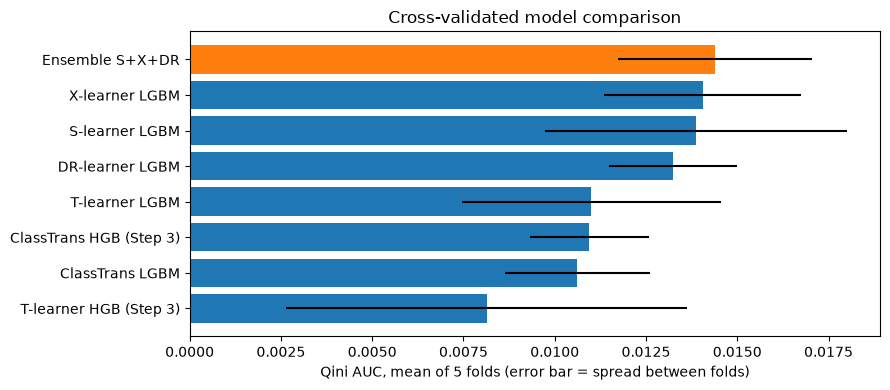

In [4]:
def metrics(y, t, u):
    return dict(qini=qini_auc_score(y, u, t), up10=uplift_at_k(y, u, t, strategy='overall', k=0.1) * 100,
                up30=uplift_at_k(y, u, t, strategy='overall', k=0.3) * 100)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
folds = list(skf.split(dev_idx, strata[dev_idx]))
rows = []
for name, fp in CANDIDATES.items():
    t0 = time.time(); r = []
    for a, b in folds:
        tr, te = dev_idx[a], dev_idx[b]
        r.append(metrics(Y[te], T[te], fp(X.iloc[tr], T[tr], Y[tr], X.iloc[te])))
    r = pd.DataFrame(r)
    rows.append({'model': name, 'qini': r.qini.mean(), 'qini_sd': r.qini.std(), 'up10': r.up10.mean(), 'up10_sd': r.up10.std(),
                 'up30': r.up30.mean(), 'up30_sd': r.up30.std(), 'secs': time.time() - t0})
    print(f"{name:26s} qini {rows[-1]['qini']:.4f}  up10 {rows[-1]['up10']:.2f}  up30 {rows[-1]['up30']:.2f}  ({rows[-1]['secs']:.0f}s)")
cvres = pd.DataFrame(rows).sort_values('qini', ascending=False).reset_index(drop=True)
display(cvres.round(4))

fig, ax = plt.subplots(figsize=(9, 4))
o = cvres.sort_values('qini')
ax.barh(o.model, o.qini, xerr=o.qini_sd, color=['tab:orange' if 'Ensemble' in m else 'tab:blue' for m in o.model])
ax.set_xlabel('Qini AUC, mean of 5 folds (error bar = spread between folds)'); ax.set_title('Cross-validated model comparison')
plt.tight_layout(); plt.show()

## Cell 4 · Record: tuning and repeat runs (done by Claude, same data and code)
**Tuning:** Optuna searched tree settings (leaves, minimum group size, learning rate, number of trees, feature sampling, regularisation), 22 trials each for S- and X-learner.
**Repeat runs:** the 5-fold comparison was rerun on 2 more random splits (seeds 7 and 99) to see if the ranking holds.

| Model | Mean Qini over 3 splits | Uplift @10% | Uplift @30% |
|---|---|---|---|
| **Ensemble S+X+DR (default settings)** | **0.0146** | 10.0 | 6.5 |
| Ensemble (tuned S and X) | 0.0147 (2 splits) | 10.2 | 6.6 |
| X-learner default | 0.0145 | 9.9 | 6.5 |
| X-learner tuned | 0.0140 | 10.2 | 6.3 |
| S-learner tuned | 0.0139 | 10.4 | 6.3 |
| DR-learner default | 0.0137 | 10.0 | 6.5 |
| S-learner default | 0.0137 | 10.2 | 6.3 |

**Lesson:** tuning won on the splits it was tuned on but **did not beat default settings on fresh splits**, so the gain was noise. The ensemble with default settings is the most consistent winner. We keep defaults: simpler and more honest.

## Cell 5 · Final exam: champion vs Step 3 baseline on the locked 20%
Both are trained on the full 80% and scored on the 40,008 customers never used for choosing. 300 bootstrap resamples give a 95% range.

,model,qini,up10,up30,qini_low95,qini_high95
0,T-learner HGB (Step 3),0.0114,8.3936,5.6372,0.0055,0.0178
1,Ensemble S+X+DR,0.0144,11.6644,6.0682,0.0084,0.0204


Improvement in Qini: +27% | top-10% lift: 8.4 -> 11.7 pts


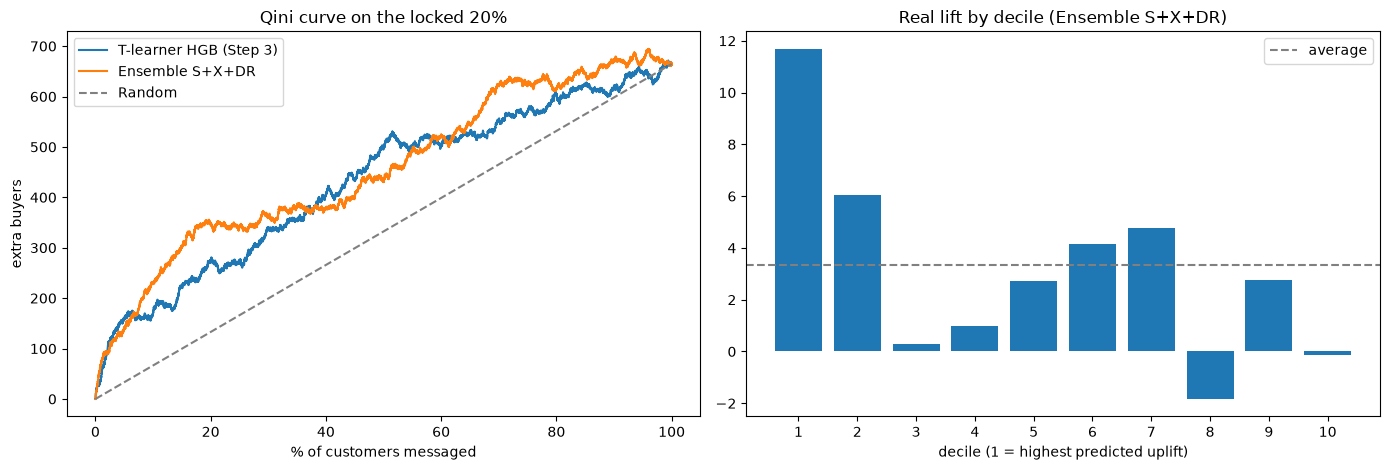

,message_top_%,share_of_extra_buyers_%
0,10,34.6
1,20,52.5
2,30,54.3
3,50,64.9


In [5]:
CHAMP = 'Ensemble S+X+DR'
Xd, Td, Yd = X.iloc[dev_idx], T[dev_idx], Y[dev_idx]; Xh, Th, Yh = X.iloc[hold_idx], T[hold_idx], Y[hold_idx]
rng = np.random.default_rng(1); B = [rng.integers(0, len(Yh), len(Yh)) for _ in range(300)]
final, hp = [], {}
for name in ['T-learner HGB (Step 3)', CHAMP]:
    u = CANDIDATES[name](Xd, Td, Yd, Xh); hp[name] = u
    bq = [qini_auc_score(Yh[b], u[b], Th[b]) for b in B]
    final.append({'model': name, **metrics(Yh, Th, u), 'qini_low95': np.percentile(bq, 2.5), 'qini_high95': np.percentile(bq, 97.5)})
final = pd.DataFrame(final); display(final.round(4))
print(f"Improvement in Qini: {100 * (final.qini[1] / final.qini[0] - 1):+.0f}% | top-10% lift: {final.up10[0]:.1f} -> {final.up10[1]:.1f} pts")

def qini_curve(y, t, u):
    o = np.argsort(-u, kind='stable'); y, t = y[o], t[o]
    nt, nc = np.cumsum(t), np.cumsum(1 - t)
    q = np.cumsum(y * t) - np.cumsum(y * (1 - t)) * np.divide(nt, nc, out=np.zeros_like(nt, dtype=float), where=nc > 0)
    return np.r_[0, np.arange(1, len(y) + 1) / len(y)], np.r_[0, q]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
for name in hp:
    x, q = qini_curve(Yh, Th, hp[name]); ax[0].plot(x * 100, q, label=name)
ax[0].plot([0, 100], [0, q[-1]], ls='--', c='grey', label='Random'); ax[0].legend(); ax[0].set_title('Qini curve on the locked 20%')
ax[0].set_xlabel('% of customers messaged'); ax[0].set_ylabel('extra buyers')
h = pd.DataFrame({'u': hp[CHAMP], 't': Th, 'y': Yh}); h['decile'] = pd.qcut(rankdata(-h.u, method='ordinal'), 10, labels=range(1, 11))
dec = h.groupby('decile', observed=True).apply(lambda g: (g[g.t == 1].y.mean() - g[g.t == 0].y.mean()) * 100, include_groups=False)
ax[1].bar(range(1, 11), dec.values); ax[1].axhline((Yh[Th == 1].mean() - Yh[Th == 0].mean()) * 100, ls='--', c='grey', label='average')
ax[1].set_xticks(range(1, 11)); ax[1].set_title(f'Real lift by decile ({CHAMP})'); ax[1].set_xlabel('decile (1 = highest predicted uplift)'); ax[1].legend()
plt.tight_layout(); plt.show()
x, q = qini_curve(Yh, Th, hp[CHAMP])
display(pd.DataFrame({'message_top_%': [10, 20, 30, 50], 'share_of_extra_buyers_%': [100 * q[int(len(Yh) * k / 100)] / q[-1] for k in [10, 20, 30, 50]]}).round(1))

## Cell 6 · Train the champion on all 200,039 and score every customer
Scores all 400,162 customers (including the unlabelled half) for the next steps (money simulator, budget optimiser). Scores are ranks from 0 to 1: higher = more persuadable.

In [6]:
t0 = time.time()
champ_scores = CANDIDATES[CHAMP](X, T, Y, allp[X_COLS].astype('float32'))
out = pd.DataFrame({'client_id': allp.client_id, 'in_experiment': allp.in_experiment, 'uplift_rank': champ_scores})
duckdb.register('out_df', out)
duckdb.sql(f"COPY out_df TO '{(FEAT / 'uplift_scores_champion.parquet').as_posix()}' (FORMAT PARQUET)")
hold_out = pd.DataFrame({'client_id': df.client_id.values[hold_idx], 'treatment_flg': Th, 'target': Yh,
                         'step3_tlearner': hp['T-learner HGB (Step 3)'], 'champion': hp[CHAMP]})
duckdb.register('hold_df', hold_out)
duckdb.sql(f"COPY hold_df TO '{(FEAT / 'holdout_scores.parquet').as_posix()}' (FORMAT PARQUET)")
print(f'scored {len(out):,} customers in {time.time()-t0:.0f}s | saved uplift_scores_champion.parquet and holdout_scores.parquet')

scored 400,162 customers in 32s | saved uplift_scores_champion.parquet and holdout_scores.parquet


## Your notes
- Which model won, and why do we trust it?
- Why did tuning not help?
- How much better is the champion than Step 3 on the final exam?